In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

# successful fits: 
# LV4 + aSyn WT                 
# LV4 + aSyn E61V
# LV4 + aSyn A124T
# LV4 + aSyn E46K
# POPG + aSyn WT
# POPG + 25uM aSyn variants
# DOPC/GM1 + aSyn WT
# DOPC/GM1 + 25uM aSyn variants
# DOPC/DOPS + aSyn WT
# DOPC/DOPS + 25uM aSyn variants

# Observables:
# 1. Median radius
# 2. Fraction of P(r) shifted to higher values (integral)

# presentation: 
# aSyn conc. against R/R0 ==> different lipid conditions
# aSyn conc. against fraction of P(r) shifted to higher values (integral) ==> different lipid conditions


In [5]:
# collect samples in sorted way
LV4 = {
    "name": "LV4",
    "pure": "BII_S9",
    "WT": [
        "BIV_S1",
        # "BIV_S2",
        # "BIV_S3",
        "BIV_S4",
        "BIV_S5",
        "BIV_S6",
        "BIV_S7",
        "BIV_S8",
        "BIV_S9",
        "BIV_S10"],
    "A124T": [
        "BIV_S21",
        "BIV_S22",
        "BIV_S23",
        "BIV_S24",
        "BIV_S25",
        "BIV_S26",
        "BIV_S27",
        "BIV_S28",
        "BIV_S29",
        "BIV_S30",],
    "E61V": [
        "BIV_S11",
        "BIV_S12",
        "BIV_S13",
        "BIV_S14",
        "BIV_S15",
        "BIV_S16",
        "BIV_S17",
        "BIV_S18",
        "BIV_S19",
        "BIV_S20",],
    "E46K": [
        "BIV_S31",
        "BIV_S32",
        "BIV_S33",
        "BIV_S34",
        "BIV_S35",
        "BIV_S36",
        "BIV_S37",
        "BIV_S38",
        "BIV_S39",
        "BIV_S40",],
}
DOPC_GM1 = {
    "name": "DOPC/GM1 (8/2)",
    "pure": "BIX_S2",
    "WT": ["BVI_S1",
           "BVI_S2",
           "BVI_S3",
           "BVI_S4",
           "BVI_S5",
           "BVI_S6",
           "BVI_S7"],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}
POPG = {
    "name": "POPG",
    "pure": "BIX_S1",
    "WT": ["BVI_S11",
           "BVI_S12",
        #    "BVI_S13", BAD BACKGROUND SUBTRACTION
           "BVI_S14",
           "BVI_S15",
           "BVI_S16",
           "BVI_S17"],
    "A124T": ["BVI_S19"],
    "E61V": ["BVI_S18"],
    "E46K": ["BVI_S20"],
}
PCPS = {
    "name": "DOPC/DOPS (8/2)",
    "pure": "BII_S11",
    "WT": [
        "BIX_S15", #: "15 mM DOPC/DOPS (8/2) + 6 μM aSynWT",
        "BIX_S16", #: "15 mM DOPC/DOPS  (8/2) + 9 μM aSynWT",
        "BIX_S17", #: "15 mM DOPC/DOPS (8/2) + 15 μM aSynWT",
        "BIX_S18", #: "15 mM DOPC/DOPS (8/2) + 25 μM aSynWT",
        "BIX_S19", #: "15 mM DOPC/DOPS (8/2) + 50 μM aSynWT",
        # "BVII_S4", #: "15 mM DOPC/DOPS (8/2) + 75 μM aSynWT", # bgr sub removed too much of the curve
        "BVII_S5", #: "15 mM DOPC/DOPS (8/2) + 100 μM aSynWT",
        ],
    "A124T": ["BVI_S9"],
    "E61V": ["BVI_S8"],
    "E46K": ["BVI_S10"],
}

BIV_S1
BIV_S4
BIV_S5
BIV_S6
BIV_S7
BIV_S8
BIV_S9
BIV_S10
BVI_S1
BVI_S2
BVI_S3
BVI_S4
BVI_S5
BVI_S6
BVI_S7
BVI_S11
BVI_S12
BVI_S14
BVI_S15
BVI_S16
BVI_S17
BIX_S15
BIX_S16
BIX_S17
BIX_S18
BIX_S19
BVII_S5


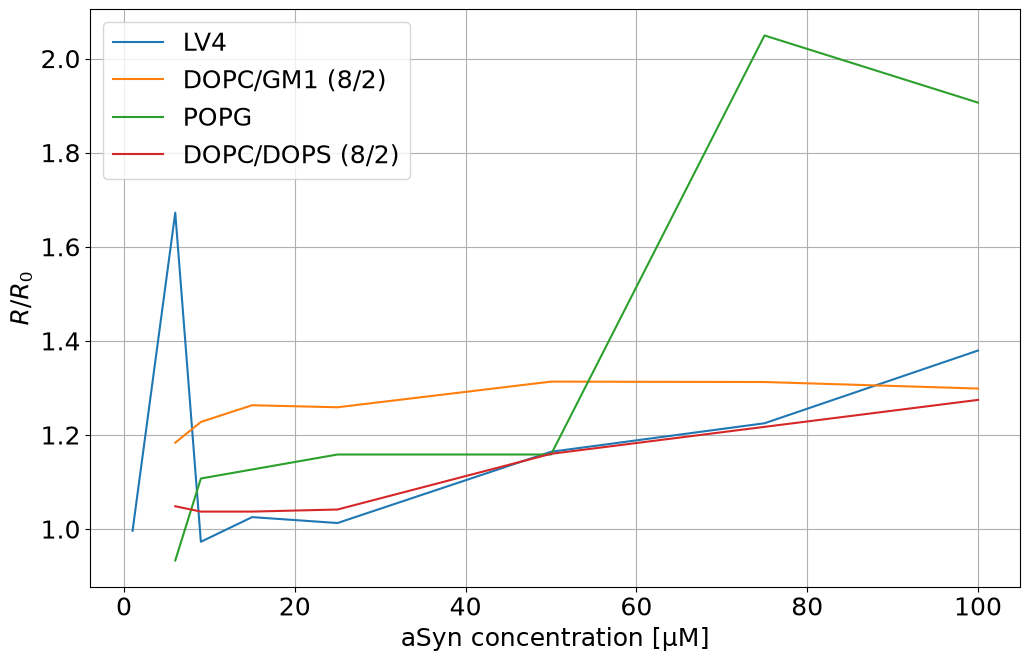

In [6]:
# Make aSyn-R/R0 plot for WT (sph. asym. lognormal)
# R0 is the median of the lognormal size distribution
succesful_series = [LV4, DOPC_GM1, POPG, PCPS]
f = plt.figure(figsize=(12, 7.5))
for series in succesful_series:
    aSyn_conc = []
    R_over_R0 = []
    if series == DOPC_GM1:
        fit_function_name = "ULV_lognormal_sph_asym_prot_layer"
    else:
        fit_function_name = "ULV_spheric_asym_C4_lognormal"
    R0 = BM29.best_fits[series["pure"]][fit_function_name][1][0]
    for sample in series["WT"]:
        print(sample)
        R = BM29.best_fits[sample][fit_function_name][1][0]
        aSyn_conc.append(BM29.concentrations[sample])
        R_over_R0.append(R/R0)
    plt.plot(aSyn_conc, R_over_R0, label=series["name"])
plt.xlabel("aSyn concentration [µM]")
plt.ylabel("$R/R_0$")
plt.grid()
plt.legend()
plt.show()


In [ ]:
import numpy as np
from scipy.stats import lognorm


def compare_lognormals(
    sigma_small, scale_small,
    sigma_large, scale_large,
    amplitude_small=1.0,
    amplitude_large=1.0
):
    """
    Find the intersections of two log-normal distributions and calculate
    the area between them for radii larger than the largest intersection.

    Parameters
    ----------
    sigma_small, sigma_large : float
        Shape parameters (sigma) of the log-normal distributions.
    scale_small, scale_large : float
        Scale parameters of scipy.stats.lognorm.
        For loc=0, these correspond to the medians of the distributions.
    amplitude_small, amplitude_large : float
        Optional multiplicative factors for the distributions.

    Returns
    -------
    dict
        intersection_radii:
            All positive intersection radii.
        tail_start:
            Largest intersection radius.
        signed_integral:
            Integral of (large distribution - small distribution)
            from tail_start to infinity.
        area_between_curves:
            Absolute area between the curves over the same interval.
    """

    ss, sl = sigma_small, sigma_large
    ms, ml = np.log(scale_small), np.log(scale_large)

    if ss <= 0 or sl <= 0 or scale_small <= 0 or scale_large <= 0:
        raise ValueError("Sigma and scale parameters must be positive.")

    # Coefficients of the quadratic equation in y = ln(r),
    # obtained by setting the two log-normal PDFs equal.
    a = 1 / (2 * ss**2) - 1 / (2 * sl**2)
    b = -ms / ss**2 + ml / sl**2
    c = (
        ms**2 / (2 * ss**2)
        - ml**2 / (2 * sl**2)
        + np.log(amplitude_large / amplitude_small)
        + np.log(ss / sl)
    )

    # Solve the quadratic equation.
    tol = 1e-12 * max(abs(a), abs(b), abs(c), 1.0)

    if abs(a) < tol:
        if abs(b) < tol:
            raise ValueError("The distributions are identical or have no unique intersection.")
        roots = [-c / b]
    else:
        discriminant = b**2 - 4 * a * c
        disc_tol = 1e-12 * max(b**2, abs(4 * a * c), 1.0)

        if discriminant < -disc_tol:
            raise ValueError("The distributions do not intersect.")

        discriminant = max(discriminant, 0.0)
        sqrt_disc = np.sqrt(discriminant)

        q = -0.5 * (b + np.copysign(sqrt_disc, b))

        if q == 0:
            roots = [-b / (2 * a)]
        else:
            roots = [q / a, c / q]

    # Convert from ln(r) to radii and remove duplicate intersections.
    intersection_radii = np.sort(np.exp(roots))
    intersection_radii = np.unique(np.round(intersection_radii, 12))

    if len(intersection_radii) == 0 or not np.all(np.isfinite(intersection_radii)):
        raise ValueError("No finite positive intersection found.")

    # Use the largest intersection: beyond this point, the curves
    # do not intersect again.
    r_cross = intersection_radii[-1]

    # Calculate the integrated difference using survival functions.
    sf_large = amplitude_large * lognorm.sf(
        r_cross, s=sl, scale=scale_large
    )
    sf_small = amplitude_small * lognorm.sf(
        r_cross, s=ss, scale=scale_small
    )

    signed_integral = sf_large - sf_small

    return {
        "intersection_radii": intersection_radii,
        "tail_start": r_cross,
        "signed_integral": signed_integral,
        "area_between_curves": abs(signed_integral)
    }

In [ ]:
result = compare_lognormals(
    sigma_small=0.35,
    scale_small=100,
    sigma_large=0.35,
    scale_large=130
)
print("Intersection:", result["tail_start"])
print("Signed integral:", result["signed_integral"])
print("Area between curves:", result["area_between_curves"])